# Doublet detection with bixverse

*Gregor Lueg*

## Intro

Doublets, droplets containing two or more cells, are a common artefact in
droplet-based single cell experiments. If left undetected, they masquerade as
intermediate cell states or novel populations and quietly corrupt downstream
analyses. This vignette demonstrates three doublet detection approaches
available in `bixverse` and benchmarks them against ground truth calls from
[demuxlet](https://github.com/statgen/demuxlet), which identifies doublets
via genetic variation across pooled donors.

`bixverse` provides three computational doublet detection methods:

- **Scrublet** is a simulation-based approach
([Wolock, et al., 2019](https://doi.org/10.1016/j.cels.2018.11.005)). It
generates synthetic doublets by averaging pairs of randomly selected cells,
embeds both real and synthetic cells together, and scores each real cell by the
proportion of its nearest neighbours that are synthetic. A bimodal score
distribution is expected: singlets cluster near zero, doublets near one. A
threshold on this score determines the final calls.

- **Boosted doublet detection** takes a different angle. Rather than scoring
against the neighbours, it repeatedly simulates doublets, clusters real and
synthetic cells together and flags clusters enriched for synthetic doublets.
A cell is called a doublet if enough iterations vote for it. This can be more
robust when the score distribution from Scrublet is not cleanly bimodal,
though it introduces its own hyperparameters (and is substantially slower).

- **scDblFinder** is a port of the
[scDblFinder](https://bioconductor.org/packages/release/bioc/html/scDblFinder.html)
method from [Germain et al.](https://pmc.ncbi.nlm.nih.gov/articles/PMC9204188/),
with one modification: it uses lightGBM with the histogram trick on the feature
space instead of xgboost, which tends to be faster to fit. It trains a
classifier on real versus synthetic doublets and combines the classifier
output with cxds co-expression scores
([Bais and Kostka](https://pmc.ncbi.nlm.nih.gov/articles/PMC7703774/)) into a
weighted final score. Across published benchmarks it tends to be the strongest
of the three.

All three methods are purely computational and work without genetic or hashing
information. They complement experimental approaches like demuxlet, which
require pooled donors or hashtag antibodies. They also have a failure mode
if a large number of doublets dominates the original data.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import bixverse as bv
from bixverse.params import BoostParams, ScdblfinderParams, ScrubletParams

## Loading the data

We use a PBMC data set with demuxlet ground truth calls. The demuxlet output
classifies each barcode as a singlet (`SNG`) or doublet (`DBL`) (or ambiguous,
but irrelevant for this situation), giving us something to benchmark against.

In [2]:
doublet_path = bv.io.download_demuxlet_pbmc()

tempdir_doublet = tempfile.TemporaryDirectory()

demuxlet_data = pl.read_csv(doublet_path / "demuxlet_calls.tsv", separator="\t")

demuxlet_data["Call"].value_counts().sort("Call")

Call,count
str,u32
"""AMB""",24
"""DBL""",1565
"""SNG""",13030


Load the data into bixverse. The matrix in this data set has the cells as
rows.

In [3]:
sc = bv.io.load_mtx(
    Path(tempdir_doublet.name) / "demuxlet",
    bv.io.get_cell_ranger_params(doublet_path, cells_as_rows=True),
)

sc

SingleCells(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmp2a89f1e1/demuxlet',
  cells=14537 (kept 14537), genes=12622,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, magic=False, residuals=False,
  stale=none
)

We also define a small helper to compute precision, recall and F1 against the
demuxlet calls. The doublet callers return the per-cell results with
`cell_idx`; we attach the barcodes and join the demuxlet calls on.

In [4]:
def with_calls(res_df: pl.DataFrame) -> pl.DataFrame:
    return res_df.with_columns(
        pl.Series("Barcode", sc.cell_ids(res_df["cell_idx"].to_numpy()))
    ).join(demuxlet_data, on="Barcode")


def doublet_metrics(predicted: pl.Series, actual: pl.Series) -> dict[str, float]:
    predicted = predicted.to_numpy()
    actual = (actual == "DBL").to_numpy()
    tp = np.sum(predicted & actual)
    fp = np.sum(predicted & ~actual)
    fn = np.sum(~predicted & actual)
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    f1 = 2 * (precision * recall) / (precision + recall)
    return {
        "precision": round(float(precision), 4),
        "recall": round(float(recall), 4),
        "f1": round(float(f1), 4),
    }

## Doublet detection methods

Let's check the three methods out and see how they behave.

### Scrublet

In [5]:
scrublet = bv.doublets.scrublet(
    sc,
    scrublet_params=ScrubletParams(expected_doublet_rate=0.12),
)

scrublet

ScrubletRes: 14537 cells, 1693 doublets (11.6%)
  Threshold:              0.2228
  Detected doublet rate:  11.6%
  Detectable fraction:    84.4%
  Overall doublet rate:   13.8%
  Simulated doublets:     21805

The score distribution for observed and simulated cells. A clean separation
between the two modes indicates the threshold is sensible.

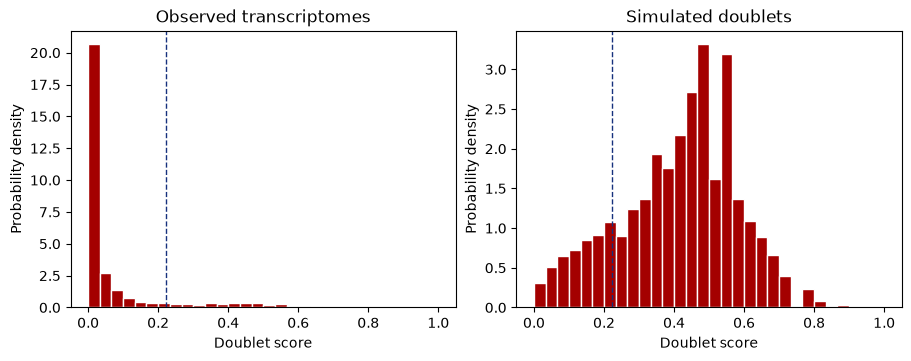

In [6]:
def plot_scrublet(res: bv.doublets.ScrubletRes, n_breaks: int = 31) -> None:
    bins = np.linspace(0, 1, n_breaks)
    fill, line = bv.pl.bx_colors("main", n=2)
    _, axes = plt.subplots(1, 2, figsize=(9, 3.5), layout="constrained")
    for ax, scores, title in zip(
        axes,
        (res.doublet_scores_obs, res.doublet_scores_sim),
        ("Observed transcriptomes", "Simulated doublets"),
        strict=True,
    ):
        ax.hist(scores, bins=bins, density=True, color=fill, edgecolor="white")
        ax.axvline(res.threshold, color=line, linestyle="--", linewidth=1)
        ax.set(title=title, xlabel="Doublet score", ylabel="Probability density")


plot_scrublet(scrublet)
plt.show()

How does the automatic thresholding perform against the demuxlet ground truth?

In [7]:
scrublet_df = with_calls(bv.doublets.get_data(scrublet))

doublet_metrics(scrublet_df["doublet"], scrublet_df["Call"])

{'precision': 0.6639, 'recall': 0.7205, 'f1': 0.6911}

If you want to add the information to the DuckDB within the object, you can
just run:

In [8]:
sc.add_obs(bv.doublets.get_data(scrublet))

sc.obs().head()

cell_idx,cell_id,nnz,lib_size,to_keep,doublet,doublet_score
u32,str,f64,f64,bool,bool,f64
0,"""AAACATACAATGCC-1""",851.0,2190.0,true,true,0.337701
1,"""AAACATACATTTCC-1""",876.0,3016.0,true,false,0.053115
2,"""AAACATACCAGAAA-1""",713.0,2481.0,true,false,0.017581
3,"""AAACATACCAGCTA-1""",948.0,3155.0,true,false,0.187289
4,"""AAACATACCATGCA-1""",337.0,703.0,true,false,0.00437


The Scrublet calls and scores are now columns in obs.

#### Manual threshold adjustment

The automatic threshold does not always land in the right place. If the score
distribution suggests a different cut-off, `call_doublets_manual` lets you
override it.

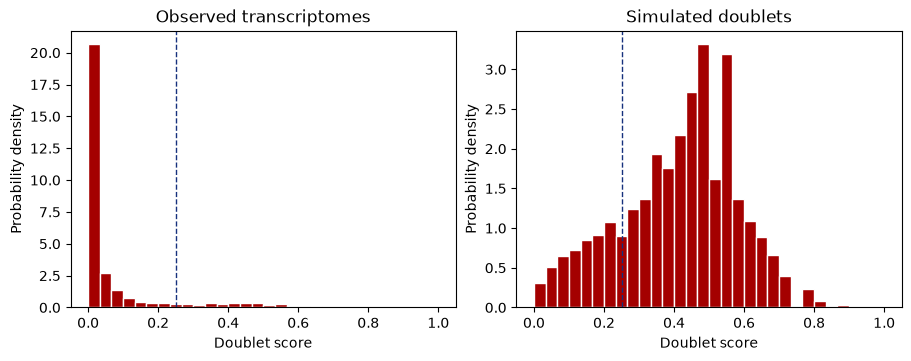

In [9]:
scrublet_adj = bv.doublets.call_doublets_manual(scrublet, threshold=0.25)

plot_scrublet(scrublet_adj)
plt.show()

In [10]:
scrublet_adj_df = with_calls(bv.doublets.get_data(scrublet_adj))

doublet_metrics(scrublet_adj_df["doublet"], scrublet_adj_df["Call"])

{'precision': 0.678, 'recall': 0.6801, 'f1': 0.679}

We have made it worse here, but maybe there are cases where the scores are not
very good. Compared to the original version, Otsu's method is used to identify
the threshold, but it might fail in some situations.

#### Running with grouping variables or within specific cell subsets

Scrublet (and the other methods) have two parameters if you wish to run the
detection method within a specific set of cells (`cells_to_use=None`) and/or
want to use a grouping variable, like running the doublet detection within
individual samples (`group_by=None`).

### Boosted doublet detection

The boosted approach repeatedly simulates doublets and clusters them together
with the real cells. This can work better when the Scrublet score distribution
is messy or unimodal. However, by default it runs 20 iterations of the
algorithm, which means 20x generation of synthetic doublets. The initial PCA
is kept for subsequent reprojection; nonetheless, this makes it slower than
the other methods in this vignette.

In [11]:
boosted_doublets = bv.doublets.doublet_detection_boost(
    sc,
    boost_params=BoostParams(),
)

boosted_doublets

BoostRes: 14537 cells, 1504 doublets (10.3%)
  Score range: [0.0164, 0.7143]

Let's check how boosted works?

In [12]:
boosted_df = with_calls(bv.doublets.get_data(boosted_doublets))

doublet_metrics(boosted_df["doublet"], boosted_df["Call"])

{'precision': 0.6636, 'recall': 0.6397, 'f1': 0.6514}

Overall, it takes longer and has worse performance (in this data set). If you
wish to have a partially orthogonal method, it can be worthwhile nonetheless.
There is also an option to accelerate the algorithm via fast clustering. This
runs k-means clustering with `sqrt(n_cells) * 4` centroids by default, the kNN
on these centroids, Louvain on the smaller kNN graph and projects the Louvain
membership back for final scoring. This comes at a cost of recall, as you can
see below. You need to check how many centroids you need to represent your
data properly. On smaller data sets, you can get away with `n_cells / 10` and
compress 10 cells into one centroid... On larger data sets, you might want to
compress further.

In [13]:
boosted_doublets_fast = bv.doublets.doublet_detection_boost(
    sc,
    boost_params=BoostParams(
        fast_cluster=True,
        # in this case, we set the n_centroids to n_cells / 10
        # you want this to not be too low; also the data is so small, we just
        # use standard k-means over mini batch
        n_centroids=1500,
        km_type="standard",
    ),
)

In [14]:
boosted_fast_df = with_calls(bv.doublets.get_data(boosted_doublets_fast))

doublet_metrics(boosted_fast_df["doublet"], boosted_fast_df["Call"])

{'precision': 0.7063, 'recall': 0.5673, 'f1': 0.6292}

### scDblFinder

Lastly, `bixverse` also provides an implementation of
[scDblFinder](https://bioconductor.org/packages/release/bioc/html/scDblFinder.html)
from [Germain et al.](https://pmc.ncbi.nlm.nih.gov/articles/PMC9204188/) with
one modification: instead of xgboost, we use an implementation of lightGBM
with the histogram trick on the feature space. This yields faster fitting
compared to the original xgboost approach. To run it, you can just do the
following:

In [15]:
scdblfinder = bv.doublets.scdblfinder(
    sc,
    scdblfinder_params=ScdblfinderParams(expected_doublet_rate=0.12),
    # if you wish to get the features that were used to train the classifier
    return_features=False,
)

scdblfinder

ScDblFinderRes: 14537 cells, 2250 doublets (15.5%)
  Threshold:        0.2874
  Score range:      [0.0079, 0.9939]
  Final clusters:   9
  Features available: FALSE

The scores are similar to the other methods.

In [16]:
scdblfinder_df = with_calls(bv.doublets.get_data(scdblfinder))

doublet_metrics(scdblfinder_df["predicted_doublets"], scdblfinder_df["Call"])

{'precision': 0.5898, 'recall': 0.8506, 'f1': 0.6966}

We can also extract the other scores from scDblFinder via `get_scores`: the
weighted score (`score_type="weighted"`) and the cxds scores
(`score_type="cxds_scores"`). The cxds scores were originally developed by
[Bais and Kostka](https://pmc.ncbi.nlm.nih.gov/articles/PMC7703774/) and are
used as an input into the classifier.

In [17]:
weighted_scores = bv.doublets.get_scores(scdblfinder, score_type="weighted")
cxds_scores = bv.doublets.get_scores(scdblfinder, score_type="cxds_scores")

pl.DataFrame({"weighted": weighted_scores, "cxds": cxds_scores}).describe()

statistic,weighted,cxds
str,f64,f64
"""count""",14537.0,14537.0
"""null_count""",0.0,0.0
"""mean""",0.209842,0.137246
"""std""",0.267855,0.121008
"""min""",0.0,0.0
"""25%""",0.02825,0.066592
"""50%""",0.086302,0.10096
"""75%""",0.268617,0.161034
"""max""",0.994834,1.0


Not ported to Python yet: `find_threshold_otsu`, so calling doublets on the
weighted or cxds scores via Otsu's method is left out here.

Should you observe that the cxds scores are very flat or you only have a few
data points (this can occur in low complexity experiments in which the highest
expressing genes are VERY similar across all the cells, for example in cell
culture experiments), you can bump `cxds_genes` up. The default here is 500,
but you might want to increase this pending your experiment.

### PCA solver and HVG method

All three methods run their own PCA on the observed and simulated cells. You
pick the solver via `svd_solver`. The default here is `"randomised"`, a
randomised SVD that is approximate in the trailing components. `"covariance"`
builds the gene x gene cross-product over the HVGs and eigendecomposes it,
which is exact, but the doublet methods run on more genes and that matrix
grows with the square of the gene count, so it gets painfully slow here.
`"auto"` (the default in `PcaParams`) runs Lanczos on the sparse path and the
covariance solver on the dense one. `"exact"` runs Lanczos on the sparse path
and a full SVD on the dense one. Scrublet and the boosted method also take the
HVG method via `hvg_method`, including the scran trend:

```python
ScrubletParams(
    expected_doublet_rate=0.12,
    hvg_method="scran",
    svd_solver="covariance",
)
```

### Conclusion

All methods can help to identify doublets in your data in a data-driven way.
In a comparison paper scDblFinder is the best across different benchmark data
sets, see [here](https://www.cell.com/cell-systems/fulltext/S2405-4712(20)30459-2).
Which one wins on this data set is in the metrics above.

## Clean up

In [18]:
tempdir_doublet.cleanup()